In [4]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import new_calcium_model, simulate_dipole

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology
 
# import pandas as pd
from scipy import signal
import sys
sys.path.append("/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_dev")
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/figures/new_hnn_model'
#os.mkdir(pathfig)

In [5]:
# net_no_drive = new_calcium_model()
# net_no_drive.clear_connectivity()

# net_no_drive.set_cell_positions(inplane_distance=30.)

# depths = list(list(range(-100,2200,200)))
# electrode_pos = [(135, 135, dep) for dep in depths]

# net_no_drive.add_electrode_array('probe1', electrode_pos)

# dpl_no_drive = simulate_dipole(net_no_drive, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')


In [6]:
# timevec = net_no_drive.cell_response.times

# window_len, scaling_factor = 20, 3000


# from hnn_core.extracellular import _get_laminar_z_coords

# contact_labels, delta = _get_laminar_z_coords(net_no_drive.rec_arrays['probe1'][0].positions)

# fig, axs = plt.subplots(5,1, figsize=(6,12))

# sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
# L = []
# for section in sections:
#     L.append(net_no_drive.cell_types["L5_pyramidal"].sections[section].L)

# prevL = 0
# for i, section in enumerate(sections):
#     v = np.array(net_no_drive.cell_response.vsec[0][171][section])
#     axs[i].plot(timevec, v)


In [7]:
window_len, scaling_factor = 2, 1000

net = new_calcium_model(mesh_shape=(1,1))
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2400,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 20

for i in range(4):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


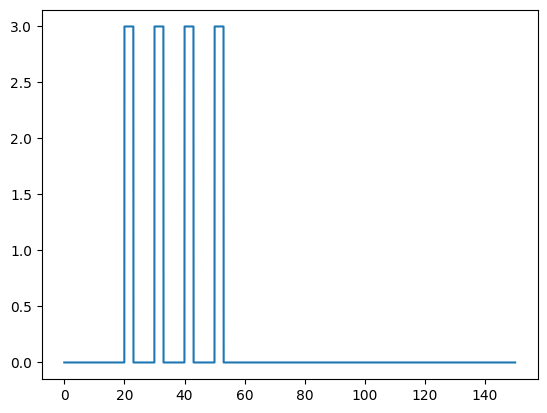

In [8]:
timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

plt.plot(timevec, clamp)


In [9]:
# I = np.array(net.cell_response.spike_gids[0]) <270
# gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
# times = np.array(net.cell_response.spike_times).reshape(-1,)[I]

# l5_first = gids[np.where(((gids > 169).astype(float) + (gids <=270).astype(float)) == 2)[0][0]]
# vltg = net.cell_response.vsec[0][int(l5_first)]
# ca = net.cell_response.ca[0][int(l5_first)]

# l5_gids = gids[np.where(((gids > 169).astype(float) + (gids <=270).astype(float)) == 2)[0]]
# l5_unique_gids = np.array([])
# for l5 in l5_gids:
#     if ~np.isin(l5,l5_unique_gids):
#         l5_unique_gids = np.append(l5_unique_gids, l5)

# ca_l5_tuft = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
# ca_l5_apcl2 = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
# vltg_l5_soma = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
# ca_l5_soma = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))

# for i, g in enumerate(l5_unique_gids.astype(int)):
#     ca_l5_tuft[i] = net.cell_response.ca[0][g]['apical_tuft']
#     ca_l5_apcl2[i] = net.cell_response.ca[0][g]['apical_2']
#     ca_l5_soma[i] = net.cell_response.ca[0][g]['apical_2']
#     vltg_l5_soma[i] = net.cell_response.vsec[0][g]['soma']

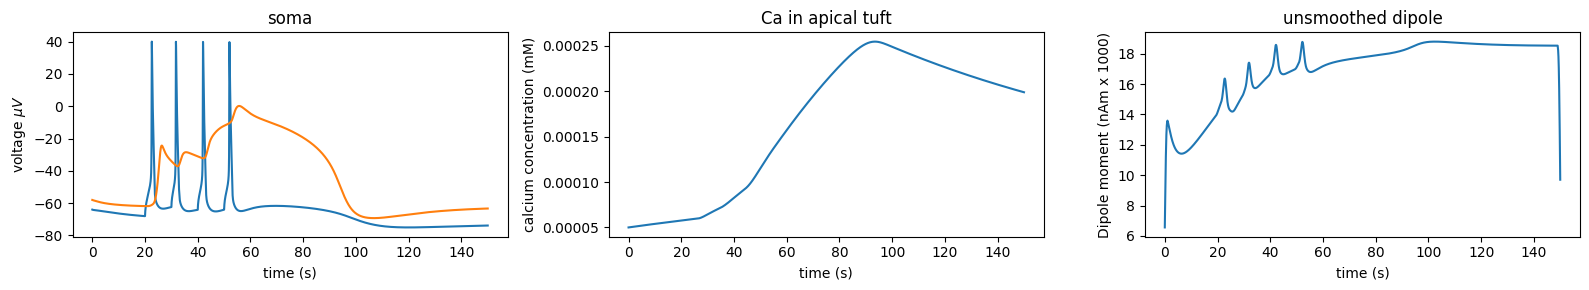

In [10]:
timevec = net.cell_response.times

gid = 3
fig, axs = plt.subplots(1,3,figsize=(16,3))
# v_int2 = net.cell_response.vsec[0][0]['soma']
# plt.plot(timevec, v_int2)
# v_l2 = net.cell_response.vsec[0][35]['soma']
# plt.plot(timevec, v_l2)
# v_int5 = net.cell_response.vsec[0][135]['soma']
# plt.plot(timevec, v_int5)
v_l5 = net.cell_response.vsec[0][gid]['soma']
v_l5_apcl = net.cell_response.vsec[0][gid]['apical_tuft']
axs[0].plot(timevec, v_l5)
axs[0].plot(timevec, v_l5_apcl)

axs[0].set_ylabel('voltage $\mu V$')
axs[0].set_title('soma')

ca_l5 = net.cell_response.ca[0][gid]['apical_tuft']

axs[1].plot(timevec, ca_l5)
axs[1].set_title('Ca in apical tuft')
axs[1].set_ylabel('calcium concentration (mM)')

axs[2].plot(timevec, dpl[0].data['L5'])
axs[2].set_title('unsmoothed dipole')
axs[2].set_ylabel('Dipole moment (nAm x 1000)')

for ax in axs:
    ax.set_xlabel('time (s)')

fig.tight_layout()
#fig.savefig(os.path.join(pathfig,'l5_electrophysio.png'))

In [11]:
net.cell_types['L5_pyramidal'].sections['basal_1'].Ra

200

In [12]:
from hnn_core.extracellular import _get_laminar_z_coords

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)

In [13]:
window_len, scaling_factor = 15, 1000

net = new_calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2400,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 20

for i in range(4):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


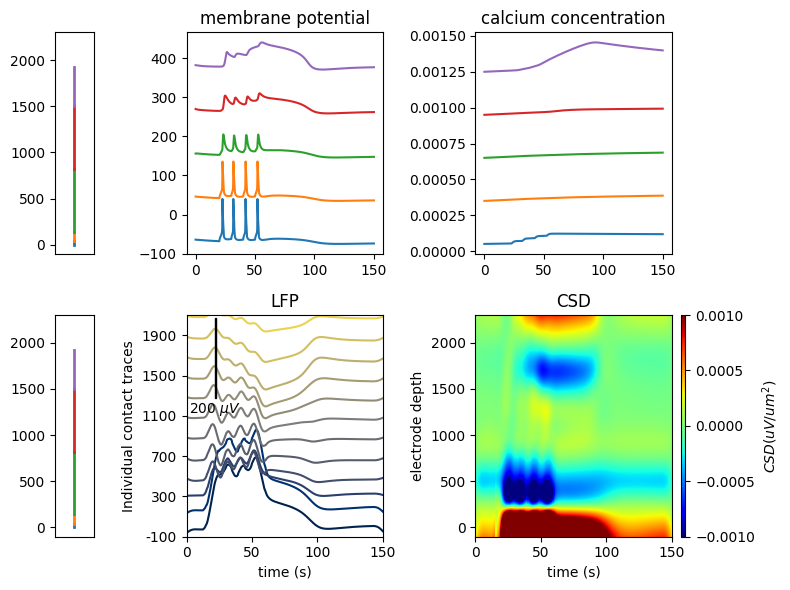

In [14]:
fig, axs = plt.subplots(2,3, figsize=(8,6), width_ratios=[0.2, 1, 1])

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net.cell_response.vsec[0][171][section])
    axs[0,1].plot(timevec, v + i*110)
    ca = np.array(net.cell_response.ca[0][171][section])
    axs[0,2].plot(timevec, ca + i*0.0003)
    prevL += L[i]


axs[0,0].set_xticks([])
axs[1,0].set_xticks([])
axs[0,1].set_title('membrane potential')
axs[0,2].set_title('calcium concentration')

new_lim = contact_labels[0:len(contact_labels):2]


net.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,1], show=False)
lfp_ticks = axs[1,1].get_yticks()
lfp_ticks = lfp_ticks[0:-1:2]

axs[1,0].set_ylim((lfp_ticks[0], lfp_ticks[-1]+50))
axs[1,1].set_yticks(lfp_ticks)
axs[1,1].set_ylim((lfp_ticks[0], lfp_ticks[-1]+50))
axs[1,1].set_xlabel('time (s)')
axs[1,1].set_title('LFP')

net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,2], show=False, vmin=-0.001, vmax=0.001)
#axs[1,2].set_yticks(new_ticks)
axs[1,2].set_title('CSD')
axs[1,2].set_ylim((-100, 2300))
axs[1,0].set_ylim(axs[1,2].get_ylim())
axs[0,0].set_ylim(axs[1,2].get_ylim())

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_lfp_csd.png'))
#fig.savefig(os.path.join(pathfig,'l5_lfp_csd.svg'))



In [15]:
def net_block_ca(net_no_ca):
    # block Ca
    # 
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_HVA'] = 0

    return net_no_ca

In [16]:
net_no_ca = new_calcium_model()
net_no_ca.clear_connectivity()

net_no_ca = block_ca(net_no_ca)


net_no_ca.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2400,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net_no_ca.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 20

for i in range(3):
    net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')

dpl_no_ca[0].smooth(window_len).scale(scaling_factor)


NameError: name 'block_ca' is not defined

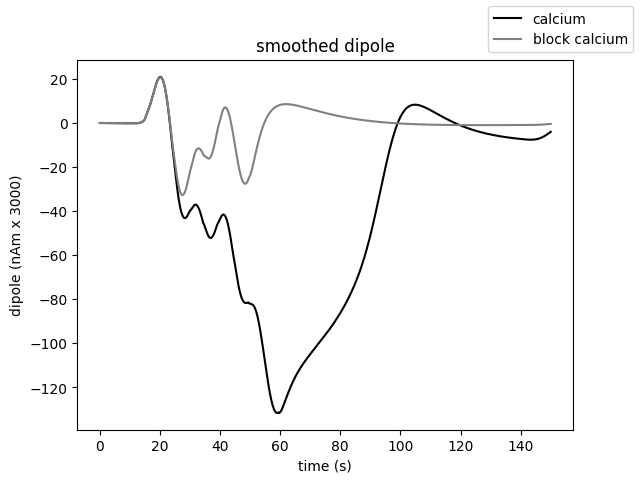

In [ ]:
fig, ax = plt.subplots()
ax.plot(timevec, dpl[0].data['L5'], color='k', label='calcium')
ax.plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5],label='block calcium')

ax.set_title('smoothed dipole')
ax.set_ylabel('dipole (nAm x 3000)')
ax.set_xlabel('time (s)')
fig.legend()
fig.savefig(os.path.join(pathfig,'dipole.png'))


In [ ]:
def stim_net(window_len =20, scaling_factor=10, block_ca=True, clear_conn=True, stim='coincidence'):
    net = new_calcium_model()

    if clear_conn:
        net.clear_connectivity()
    
    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2400,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    if block_ca:
        net = net_block_ca(net)


    if stim == 'coincidence':
        net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_prox',amplitude=3,t0=t0,tstop=t0+3)
        net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_dist',amplitude=0.3,t0=t0+3,tstop=t0+6)
    elif stim == 'distal':
        net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_dist',amplitude=1.5,t0=t0,tstop=t0+3)

    dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
    dpl[0].smooth(window_len).scale(scaling_factor)

    return net, dpl


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 

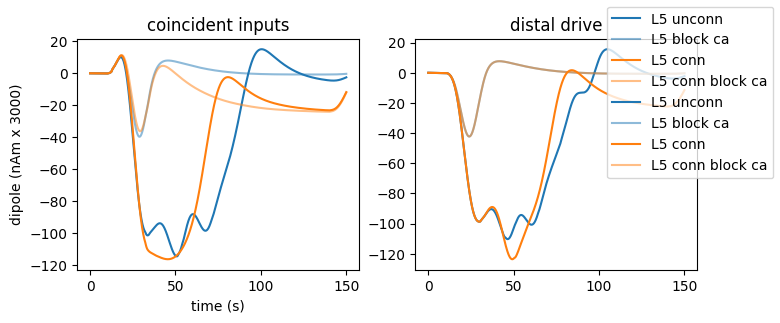

In [ ]:

fig, ax = plt.subplots(1,2, figsize=(8,3))

window_len, scaling_factor = 20, 1000


# dipole coincidence detection

_, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=True, stim='coincidence')

# no conn dipole
ax[0].plot(timevec, dpl[0].data['L5'], color='tab:blue')

_, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=True, stim='coincidence')

ax[0].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:blue', alpha=0.5)

# conn dipole
net, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=False, stim='coincidence')
ax[0].plot(timevec, dpl[0].data['L5'], color='tab:orange')

net_no_ca, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=False, stim='coincidence')
ax[0].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:orange', alpha=0.5)

# dipole distal drive
_, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=True, stim='distal')
ax[1].plot(timevec, dpl[0].data['L5'], color='tab:blue', label='L5 unconn')
_, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=True, stim='distal')
ax[1].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:blue', label='L5 block ca', alpha=0.5)
net, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=False, stim='distal')
ax[1].plot(timevec, dpl[0].data['L5'], color='tab:orange', label='L5 conn')
net_no_ca, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=False, stim='distal')
ax[1].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:orange', label='L5 conn block ca', alpha=0.5)

ax[0].set_title('coincident inputs')
ax[1].set_title('distal drive')
ax[0].set_ylabel('dipole (nAm x 3000)')
ax[0].set_xlabel('time (s)')
ax[0].set_xlabel('time (s)')

fig.legend()
fig.savefig(os.path.join(pathfig,'dipole_beta_events.png'))

In [ ]:
fig, axs = plt.subplots(2,3, figsize=(8,6), width_ratios=[0.2, 1, 1])

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net_no_ca.cell_types["L5_pyramidal"].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net_no_ca.cell_response.vsec[0][171][section])
    axs[0,1].plot(timevec, v + i*110)
    ca = np.array(net_no_ca.cell_response.ca[0][171][section])
    axs[0,2].plot(timevec, ca + i*0.0003)
    prevL += L[i]


axs[0,0].set_xticks([])
axs[1,0].set_xticks([])
axs[0,1].set_title('membrane potential')
axs[0,2].set_title('calcium concentration')

new_lim = contact_labels[0:len(contact_labels):2]


net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,1], show=False)
lfp_ticks = axs[1,1].get_yticks()
lfp_ticks = lfp_ticks[0:-1:2]

axs[1,0].set_ylim((lfp_ticks[0], lfp_ticks[-1]+50))
axs[1,1].set_yticks(lfp_ticks)
axs[1,1].set_ylim((lfp_ticks[0], lfp_ticks[-1]+50))
axs[1,1].set_xlabel('time (s)')
axs[1,1].set_title('LFP')

net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,2], show=False, vmin=-0.001, vmax=0.001)
#axs[1,2].set_yticks(new_ticks)
axs[1,2].set_title('CSD')
axs[1,2].set_ylim((-100, 2300))
axs[1,0].set_ylim(axs[1,2].get_ylim())
axs[0,0].set_ylim(axs[1,2].get_ylim())

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_no_ca.png'))
#fig.savefig(os.path.join(pathfig,'l5_lfp_csd_no_ca.svg'))


In [ ]:
# distal drive 
net = new_calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2400,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 1.5
t0 = 30

net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0,tstop=t0+3)

dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)


net_no_ca = new_calcium_model()
net_no_ca.clear_connectivity()

# block Ca
# 
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for section in sections:
    net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
    net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_HVA'] = 0


net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0,tstop=t0+3)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl_no_ca[0].smooth(window_len).scale(scaling_factor)


fig, ax = plt.subplots()
ax.plot(timevec, dpl[0].data['L5'], color='k', label='calcium')
ax.plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5],label='block calcium')

ax.set_title('smoothed dipole')
ax.set_ylabel('dipole (nAm x 3000)')
ax.set_xlabel('time (s)')
fig.legend()
fig.savefig(os.path.join(pathfig,'dipole_distal_drive.png'))


In [ ]:
# refractory period?
# Sarah used a proximal drive, so this is not exactly comparable

window_len, scaling_factor = 20, 3000

fig, ax = plt.subplots()

ampl = 1.5
t0 = 20

second_drive_times = np.arange(50, 200, 20)


for dt in second_drive_times:

    net = new_calcium_model()
    net.clear_connectivity()

    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='soma_1',amplitude=3,t0=t0+3,tstop=t0+3+3)
    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='soma_2',amplitude=3,t0=t0+dt+3,tstop=t0+dt+3+3)

    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='distal_1',amplitude=1,t0=t0+3,tstop=t0+3+3)
    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='distal_2',amplitude=1,t0=t0+dt+3,tstop=t0+dt+3+3)

    dpl = simulate_dipole(net, tstop=240, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
    dpl[0].smooth(window_len).scale(scaling_factor)

    ax.plot(dpl[0].times, dpl[0].data['L5'], label='second drive at '+str(dt)+' ms')

fig.legend()

fig.savefig(os.path.join(pathfig,'dipole_refractory.png'))


In [ ]:
fig, axs = plt.subplots(1,4, figsize=(12,4))

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    axs[0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net.cell_response.vsec[0][171][section])
    axs[1].plot(timevec, v + i*110)
    ca = np.array(net.cell_response.ca[0][171][section])
    axs[2].plot(timevec, ca + i*0.0003)
    prevL += L[i]

axs[3].plot(timevec, dpl[0].data['agg'])

fig.tight_layout()